In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

from PIL import Image
from src.models import *
from src.CIBISA import *
from src.utils import *

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')

torch.manual_seed(0)

transform = torchvision.transforms.Compose([torchvision.transforms.Resize((224,224)),
                            torchvision.transforms.ToTensor()])

In [3]:
architecture = 'VGG'

if architecture == 'VGG':
    model = VGG_emb()
    model = model.to(device)
    model.eval()
elif architecture == 'ResNET':
    model = ResNET_emb()
    model = model.to(device)
    model.eval()
elif architecture == 'ViT':
    model = ViT16_emb()
    model = model.to(device)
    model.eval()
elif architecture == 'Dino':
    model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
    model = model.to(device)
    model.eval()

In [4]:
pil_img1 = Image.open('./test_images/test_image12.JPEG').convert('RGB')
pil_img2 = Image.open('./test_images/test_image13.JPEG').convert('RGB')

img1 = transform(pil_img1)
img2 = transform(pil_img2)

x1 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img1)
x2 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img2)

x1 = x1[None,...].to(device)
x2 = x2[None,...].to(device)

In [5]:
p1,p2 = compute_pairs(x1=x1, x2=x2, model=model, mode='diff', loss_mode='cosine_sim', n_masks=20, beta=10, learnable_param=True)
# n1,n2 = compute_pairs(x1=x1, x2=x2, model=model, mode='neg', n_masks=20, beta=10)

TypeError: unsupported operand type(s) for -: 'tuple' and 'tuple'

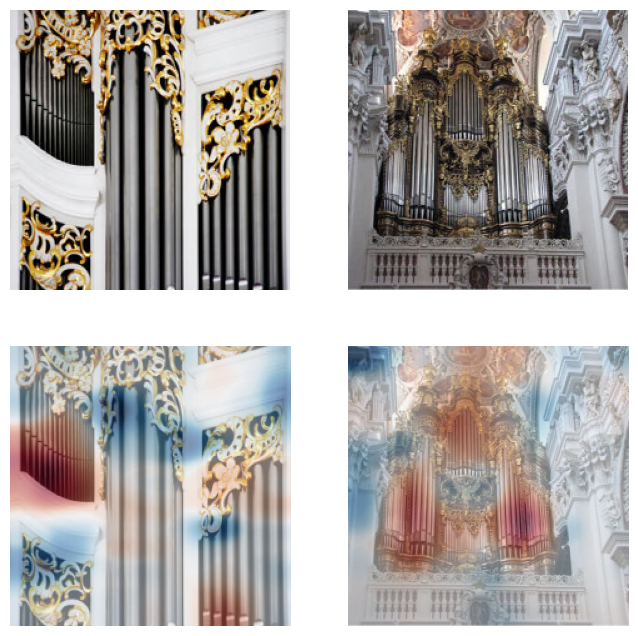

In [ ]:
# plot_pairs(pil_img1, pil_img2, p1, p2, cmap='Reds')
plot_pairs(pil_img1, pil_img2, p1, p2, cmap='RdBu_r')

In [ ]:
# f, ax = plt.subplots(2,4, figsize=(12,6))
# ax[0][0].imshow(pil_img1.resize((224,224)))
# ax[0][0].axis('off')

# ax[1][0].imshow(pil_img2.resize((224,224)))
# ax[1][0].axis('off')

# ax[0][1].imshow(pil_img1.resize((224,224)))
# ax[0][1].imshow(p1, cmap='Reds', alpha=0.6)
# ax[0][1].title.set_text('Why similar?')
# ax[0][1].axis('off')

# ax[1][1].imshow(pil_img2.resize((224,224)))
# ax[1][1].imshow(p2, cmap='Reds', alpha=0.6)
# ax[1][1].axis('off')


# ax[0][2].imshow(pil_img1.resize((224,224)))
# ax[0][2].imshow(n1, cmap='Blues', alpha=0.6)
# ax[0][2].title.set_text('Why different?')
# ax[0][2].axis('off')

# ax[1][2].imshow(pil_img2.resize((224,224)))
# ax[1][2].imshow(n2, cmap='Blues', alpha=0.6)
# ax[1][2].axis('off')

# ax[0][3].imshow(pil_img1.resize((224,224)))
# ax[0][3].imshow(p1-n1, cmap='RdBu_r', alpha=0.6)
# ax[0][3].title.set_text('Contrastive')
# ax[0][3].axis('off')

# ax[1][3].imshow(pil_img2.resize((224,224)))
# ax[1][3].imshow(p2 - n2, cmap='RdBu_r', alpha=0.6)
# ax[1][3].axis('off')

# plt.show()